# CIS 3400 — Python API Client: NYC Crashes + Historical Weather
**Wednesday, November 4, 2026 | Instructor demonstration**  
**Study period:** January 1–March 31, 2025  

**Goal:** Retrieve two real datasets via HTTP GET, transform timestamps, and merge hourly weather onto individual crashes.

**Sources:** [NYC Open Data collisions](https://data.cityofnewyork.us/d/h9gi-nx95) · [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)

**Note:** Weather is estimated for one central NYC location (not at each crash location). These data support exploration, not causal conclusions.

## 1. Imports and study settings
Both APIs return JSON. `requests` handles HTTP; pandas handles tables.

In [6]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

START_DATE = "2025-01-01"
END_DATE = "2025-03-31"
# Central Manhattan reference location (approximate); not each crash's location.
LAT, LON = 40.7580, -73.9855


## 2. GET collision data from NYC Open Data
The API field names are `crash_date` and `crash_time`; time is text like `14:35`. We request only selected fields and only our study period. Pagination prevents the default API row limit from truncating results.

In [7]:
crash_url = "https://data.cityofnewyork.us/resource/h9gi-nx95.json"
params = {
    "$select": "collision_id,crash_date,crash_time,borough,number_of_persons_injured,number_of_persons_killed",
    "$where": "crash_date >= '2025-01-01T00:00:00' AND crash_date < '2025-04-01T00:00:00'",
    "$order": "collision_id",
    "$limit": 50000,
    "$offset": 0,
}
records = []
while True:
    response = requests.get(crash_url, params=params, timeout=60)
    print("NYC API HTTP status:", response.status_code)
    response.raise_for_status()
    batch = response.json()
    records.extend(batch)
    if len(batch) < params["$limit"]:
        break
    params["$offset"] += params["$limit"]

crashes = pd.DataFrame(records)
print("Crash records:", len(crashes))
assert not crashes.empty, "No crash records returned; check API and date range."
display(crashes.head())

NYC API HTTP status: 200
Crash records: 19505


,collision_id,crash_date,crash_time,borough,number_of_persons_injured,number_of_persons_killed
0,0005ad16cba408591aaf0ff1d8765e01,2025-03-20T00:00:00.000,12:00,BROOKLYN,1,0
1,00069f2aef063cde04c78ade32cbf429,2025-02-05T00:00:00.000,17:41,MANHATTAN,0,1
2,000831f1ecb91f41f853b903f063dcce,2025-01-21T00:00:00.000,12:45,BRONX,0,0
3,0009bbf6836e8a217800e2a2effcfe4f,2025-03-23T00:00:00.000,17:45,BROOKLYN,0,0
4,0012bb8b5efaf37a37748dc28e9d3512,2025-03-23T00:00:00.000,12:00,MANHATTAN,1,0


## 3. GET historical hourly weather from Open-Meteo
`timezone=America/New_York` returns NYC local clock time. This is essential because crash times are local clock times. Historical data are model/reanalysis estimates, not a measurement at every crash site.

In [8]:
weather_url = "https://archive-api.open-meteo.com/v1/archive"
weather_params = {
    "latitude": LAT,
    "longitude": LON,
    "start_date": START_DATE,
    "end_date": END_DATE,
    "daily": "sunrise,sunset",
    "hourly": "temperature_2m,precipitation,rain,snowfall,wind_speed_10m,wind_gusts_10m,relative_humidity_2m",
    "temperature_unit": "fahrenheit",
    "wind_speed_unit": "mph",
    "precipitation_unit": "inch",
    "timezone": "America/New_York",
}
response = requests.get(weather_url, params=weather_params, timeout=60)
print("Weather API HTTP status:", response.status_code)
response.raise_for_status()
weather_json = response.json()
assert "hourly" in weather_json, weather_json
weather = pd.DataFrame(weather_json["hourly"])
print("Weather hourly records:", len(weather))
display(weather.head())

Weather API HTTP status: 200
Weather hourly records: 2160


,time,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,wind_gusts_10m,relative_humidity_2m
0,2025-01-01T00:00,45.5,0.035,0.035,0.0,9.3,23.7,96
1,2025-01-01T01:00,46.2,0.000,0.000,0.0,4.8,18.1,97
2,2025-01-01T02:00,46.7,0.000,0.000,0.0,5.4,10.1,99
3,2025-01-01T03:00,46.7,0.000,0.000,0.0,5.5,10.3,98
4,2025-01-01T04:00,45.7,0.000,0.000,0.0,6.2,11.6,99


## 4. Create the shared merge key: local date + hour
For a crash at 14:35, `.dt.floor("h")` creates 14:00. The corresponding weather record is labeled 14:00. The study ends before daylight-saving time ends; the spring clock change means one local hour does not occur.

In [9]:
# Combine the crash date with the separate HH:MM crash time.
crashes["crash_datetime"] = pd.to_datetime(
    crashes["crash_date"].str[:10] + " " + crashes["crash_time"],
    errors="coerce"
)
crashes["hour_key"] = crashes["crash_datetime"].dt.floor("h")
weather["hour_key"] = pd.to_datetime(weather["time"], errors="coerce")

print("Missing crash times:", crashes["hour_key"].isna().sum())
print("Duplicate weather hour keys:", weather["hour_key"].duplicated().sum())
assert weather["hour_key"].is_unique, "Weather must have only one record per hour."
display(crashes[["crash_date", "crash_time", "crash_datetime", "hour_key"]].head())
display(weather[["time", "hour_key", "temperature_2m", "precipitation"]].head())

Missing crash times: 0
Duplicate weather hour keys: 0


,crash_date,crash_time,crash_datetime,hour_key
0,2025-03-20T00:00:00.000,12:00,2025-03-20 12:00:00,2025-03-20 12:00:00
1,2025-02-05T00:00:00.000,17:41,2025-02-05 17:41:00,2025-02-05 17:00:00
2,2025-01-21T00:00:00.000,12:45,2025-01-21 12:45:00,2025-01-21 12:00:00
3,2025-03-23T00:00:00.000,17:45,2025-03-23 17:45:00,2025-03-23 17:00:00
4,2025-03-23T00:00:00.000,12:00,2025-03-23 12:00:00,2025-03-23 12:00:00


,time,hour_key,temperature_2m,precipitation
0,2025-01-01T00:00,2025-01-01 00:00:00,45.5,0.035
1,2025-01-01T01:00,2025-01-01 01:00:00,46.2,0.000
2,2025-01-01T02:00,2025-01-01 02:00:00,46.7,0.000
3,2025-01-01T03:00,2025-01-01 03:00:00,46.7,0.000
4,2025-01-01T04:00,2025-01-01 04:00:00,45.7,0.000


## 5. Merge: many crashes → one weather observation
A **left join** preserves all crash rows. `validate="many_to_one"` protects against accidental row multiplication. `_merge` identifies unmatched rows.

In [10]:
weather_for_merge = weather.drop(columns=["time"])
merged = crashes.merge(
    weather_for_merge,
    on="hour_key",
    how="left",
    validate="many_to_one",
    indicator=True,
)
print("Crashes before:", len(crashes), "| After merge:", len(merged))
print(merged["_merge"].value_counts(dropna=False))
assert len(merged) == len(crashes), "The merge unexpectedly changed row count."
print("Match rate:", f"{(merged['_merge'] == 'both').mean():.1%}")
display(merged[["crash_datetime", "borough", "temperature_2m", "precipitation", "wind_speed_10m", "_merge"]].head(10))

Crashes before: 19505 | After merge: 19505
_merge
both          19505
left_only         0
right_only        0
Name: count, dtype: int64
Match rate: 100.0%


,crash_datetime,borough,temperature_2m,precipitation,wind_speed_10m,_merge
0,2025-03-20 12:00:00,BROOKLYN,49.0,0.000,10.3,both
1,2025-02-05 17:41:00,MANHATTAN,30.9,0.000,1.8,both
2,2025-01-21 12:45:00,BRONX,13.9,0.000,3.3,both
3,2025-03-23 17:45:00,BROOKLYN,44.6,0.000,3.5,both
4,2025-03-23 12:00:00,MANHATTAN,40.5,0.000,5.4,both
5,2025-03-07 13:35:00,BROOKLYN,43.1,0.000,18.8,both
6,2025-03-08 18:50:00,BROOKLYN,36.6,0.000,10.5,both
7,2025-02-12 23:50:00,QUEENS,31.9,0.008,7.4,both
8,2025-01-11 23:07:00,MANHATTAN,28.0,0.000,9.8,both
9,2025-03-21 03:14:00,BROOKLYN,42.3,0.016,13.3,both


In [11]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19505 entries, 0 to 19504
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   collision_id               19505 non-null  object        
 1   crash_date                 19505 non-null  object        
 2   crash_time                 19505 non-null  object        
 3   borough                    15408 non-null  object        
 4   number_of_persons_injured  19505 non-null  object        
 5   number_of_persons_killed   19505 non-null  object        
 6   crash_datetime             19505 non-null  datetime64[ns]
 7   hour_key                   19505 non-null  datetime64[ns]
 8   temperature_2m             19505 non-null  float64       
 9   precipitation              19505 non-null  float64       
 10  rain                       19505 non-null  float64       
 11  snowfall                   19505 non-null  float64       
 12  wind

## 6. Explore rain and daylight versus darkness

First compare rainy and non-rainy hours. Then classify each hourly observation as **daylight** or **dark** using NYC sunrise and sunset times from Open-Meteo. We use the midpoint of each hour (e.g., 7:30 for 7:00–7:59), which is a simple approximation near dawn and dusk. Compare **crashes per observed hour**, not just total crashes, because daylight and darkness have different numbers of hours.


Crash counts by hourly precipitation category:


,crashes,mean_temp_F
rain_hour,,
False,17031,34.814855
True,2474,38.687591


,hours,mean_crashes_per_hour
rain_hour,,
False,1915,8.893473
True,245,10.097959


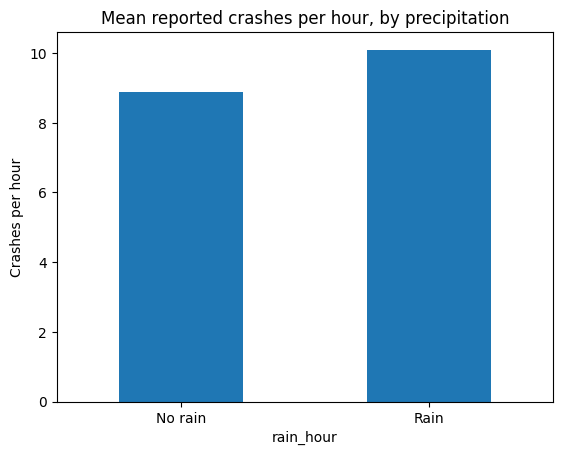

In [12]:
matched = merged.loc[merged["_merge"] == "both"].copy()
matched["rain_hour"] = matched["precipitation"].gt(0)
print("Crash counts by hourly precipitation category:")
display(matched.groupby("rain_hour").agg(crashes=("collision_id", "count"), mean_temp_F=("temperature_2m", "mean")))

# Better comparison: crashes per observed hour in each category.
hourly_crash_counts = matched.groupby("hour_key").size().rename("crash_count")
hourly_summary = weather[["hour_key", "precipitation"]].copy()
hourly_summary = hourly_summary.merge(hourly_crash_counts, on="hour_key", how="left")
hourly_summary["crash_count"] = hourly_summary["crash_count"].fillna(0)
hourly_summary["rain_hour"] = hourly_summary["precipitation"].gt(0)
display(hourly_summary.groupby("rain_hour").agg(hours=("hour_key", "count"), mean_crashes_per_hour=("crash_count", "mean")))
hourly_summary.groupby("rain_hour")["crash_count"].mean().rename(index={False:"No rain",True:"Rain"}).plot.bar(title="Mean reported crashes per hour, by precipitation", ylabel="Crashes per hour", rot=0)
plt.show()

## 7. Compare crashes during daylight and dark hours

Sunrise and sunset vary by date. Rather than assuming fixed daylight hours, we obtain the actual daily solar times through the same weather API.


Crashes during daylight versus dark hours:


,observed_hours,total_crashes,mean_crashes_per_hour
light_period,,,
Dark,1184,8676.0,7.327703
Daylight,976,10829.0,11.095287


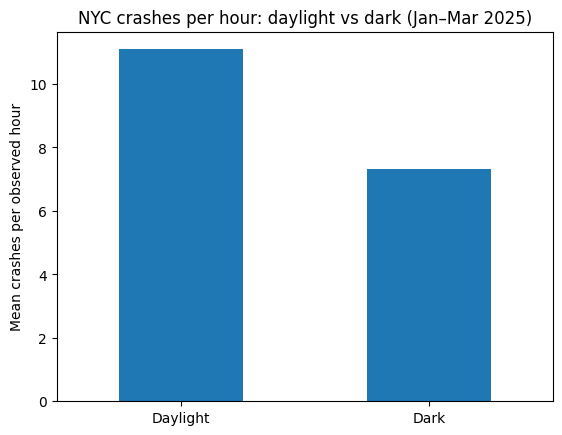

hours  mean_crashes_per_hour
light_period rain_hour                              
Dark         False       1038               6.971098
             True         146               9.863014
Daylight     False        877              11.168757
             True          99              10.444444

In [13]:
# Open-Meteo returns sunrise and sunset for each local calendar date.
sun = pd.DataFrame(weather_json["daily"])[["time", "sunrise", "sunset"]].copy()
sun["date"] = pd.to_datetime(sun["time"]).dt.date
sun["sunrise"] = pd.to_datetime(sun["sunrise"])
sun["sunset"] = pd.to_datetime(sun["sunset"])

# Label the weather hours (including hours with zero reported crashes).
hourly_summary["date"] = hourly_summary["hour_key"].dt.date
hourly_summary = hourly_summary.merge(
    sun[["date", "sunrise", "sunset"]], on="date", how="left", validate="many_to_one"
)
assert hourly_summary[["sunrise", "sunset"]].notna().all().all(), "Missing solar times"
hour_midpoint = hourly_summary["hour_key"] + pd.Timedelta(minutes=30)
hourly_summary["light_period"] = "Dark"
hourly_summary.loc[
    hour_midpoint.ge(hourly_summary["sunrise"]) & hour_midpoint.lt(hourly_summary["sunset"]),
    "light_period"
] = "Daylight"

# Attach the same light-period label to individual crash records.
merged = merged.merge(
    hourly_summary[["hour_key", "light_period"]],
    on="hour_key", how="left", validate="many_to_one"
)

light_comparison = hourly_summary.groupby("light_period").agg(
    observed_hours=("hour_key", "size"),
    total_crashes=("crash_count", "sum"),
    mean_crashes_per_hour=("crash_count", "mean"),
)
print("Crashes during daylight versus dark hours:")
display(light_comparison)
light_comparison["mean_crashes_per_hour"].reindex(["Daylight", "Dark"]).plot.bar(
    title="NYC crashes per hour: daylight vs dark (Jan–Mar 2025)",
    ylabel="Mean crashes per observed hour", xlabel="", rot=0
)
plt.show()

# Optional: see whether the rain pattern differs between daylight and darkness.
display(hourly_summary.groupby(["light_period", "rain_hour"]).agg(
    hours=("hour_key", "size"),
    mean_crashes_per_hour=("crash_count", "mean")
))


,total_crashes,injury_or_fatal_crashes,pct_injury_or_fatal
hour,,,
0,832,336,40.38
1,395,128,32.41
2,343,126,36.73
3,376,109,28.99
4,382,131,34.29
5,423,145,34.28
6,541,241,44.55
7,785,350,44.59
8,1119,445,39.77


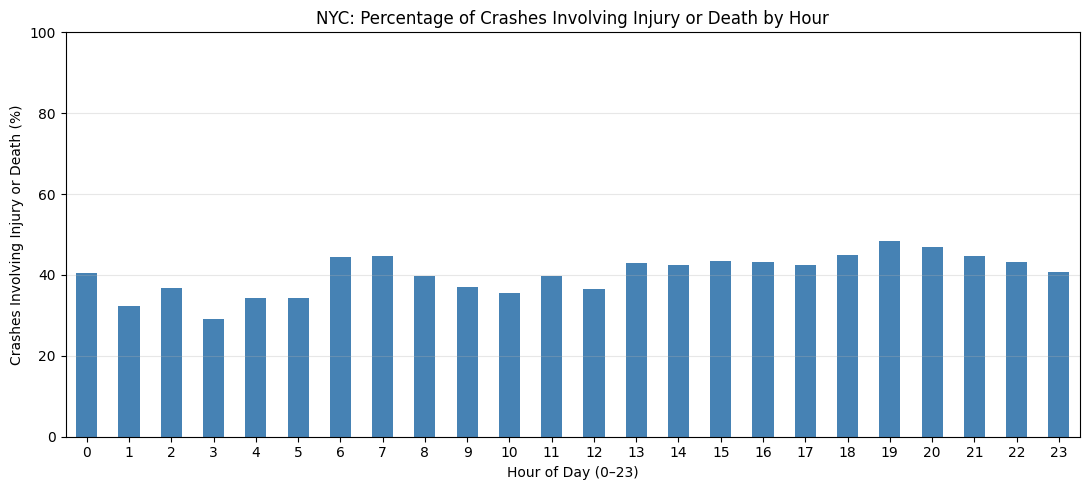

In [14]:
# NYC Crash Severity by Hour of Day

# Extract hour from crash timestamp
merged["hour"] = merged["hour_key"].dt.hour

# Convert injury and fatality columns to numeric
merged["number_of_persons_injured"] = pd.to_numeric(
    merged["number_of_persons_injured"], errors="coerce"
)

merged["number_of_persons_killed"] = pd.to_numeric(
    merged["number_of_persons_killed"], errors="coerce"
)

# Keep records with known injury and fatality counts
crashes = merged.dropna(subset=[
    "number_of_persons_injured",
    "number_of_persons_killed"
]).copy()

# Identify crashes involving injury or death
crashes["injury_or_fatal"] = (
    (crashes["number_of_persons_injured"] > 0) |
    (crashes["number_of_persons_killed"] > 0)
)

# Group by hour
hourly_severity = crashes.groupby("hour").agg(
    total_crashes=("injury_or_fatal", "size"),
    injury_or_fatal_crashes=("injury_or_fatal", "sum")
)

# Percentage of crashes involving injury or death
hourly_severity["pct_injury_or_fatal"] = (
    hourly_severity["injury_or_fatal_crashes"]
    / hourly_severity["total_crashes"] * 100
)

display(hourly_severity.round(2))

# Plot
import matplotlib.pyplot as plt

hourly_severity["pct_injury_or_fatal"].plot(
    kind="bar",
    figsize=(11, 5),
    color="steelblue"
)

plt.title("NYC: Percentage of Crashes Involving Injury or Death by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Crashes Involving Injury or Death (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

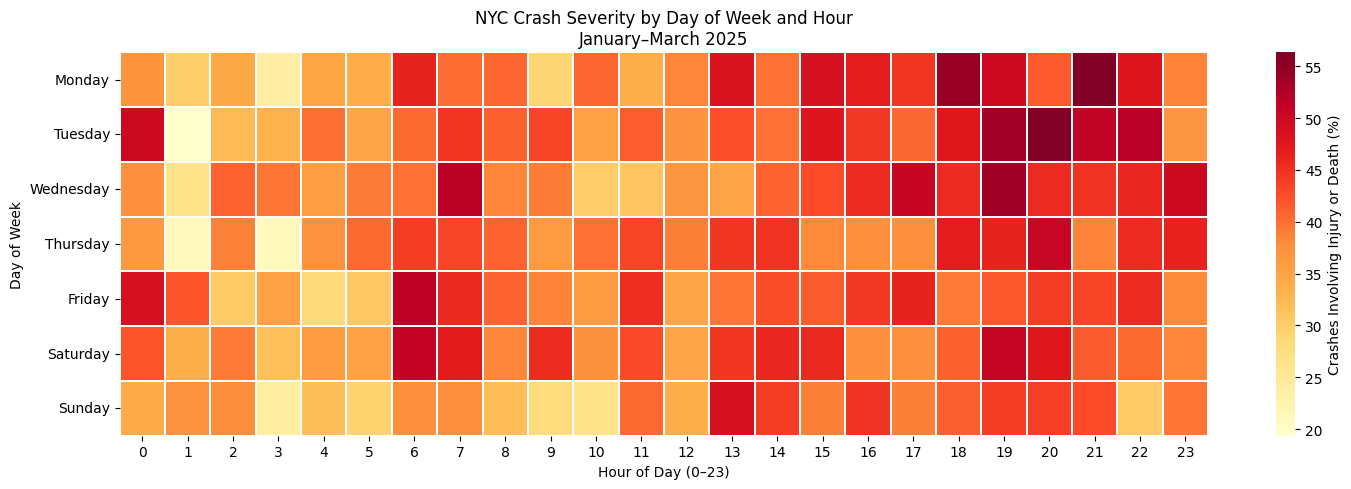

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract hour and day of week
crashes["hour"] = crashes["hour_key"].dt.hour
crashes["day_of_week"] = crashes["hour_key"].dt.day_name()

# Calculate percentage of crashes involving injury or death
heatmap_data = (
    crashes.groupby(["day_of_week", "hour"])["injury_or_fatal"]
    .mean()
    .mul(100)
    .unstack("hour")
)

# Order days Monday through Sunday
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

heatmap_data = heatmap_data.reindex(
    index=day_order,
    columns=range(24)
)

# Create heat map
plt.figure(figsize=(15, 5))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.3,
    cbar_kws={
        "label": "Crashes Involving Injury or Death (%)"
    }
)

plt.title(
    "NYC Crash Severity by Day of Week and Hour\n"
    "January–March 2025"
)
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.show()

## 8. Save your merged dataset

In [16]:
output = "nyc_crashes_weather_jan_mar_2025.csv"
merged.drop(columns=["_merge"]).to_csv(output, index=False)
print("Saved:", output)
# In Google Colab, optionally download:
# from google.colab import files
# files.download(output)

Saved: nyc_crashes_weather_jan_mar_2025.csv


## Discussion questions
1. Why did we join on **date and hour**, not just date?

To get more accurate weather data

2. Why is this a **many-to-one** merge?

Many crashes can happen in the same hour

3. What would happen if the weather data were in UTC but crashes were in NYC local time?

It would be incaccurate because they do not equal each other

4. What does `_merge == "left_only"` tell us?

Every record from the left will be represented

5. Why do we compare crashes **per observed hour** rather than total crashes for daylight versus darkness?

There are different amount of crashes during daylight/rush hour and the dark.

6. Does a higher crash count during rainy or dark hours prove that weather or darkness causes crashes? Consider traffic volume and seasonality.

No

### Optional extension
Use the `borough` field to compare patterns by borough. For more accurate weather exposure, use crash latitude/longitude to obtain weather from several locations instead of one central NYC point.

**Instructor timing:** 3 min architecture/API URLs · 5 min requests/JSON · 4 min datetime alignment · 5 min merge validation · 3 min discussion. API downloads can take extra time, so run the notebook once before class and keep its output cached.